<a href="https://colab.research.google.com/github/619carey/ai-ml-coursework-projects/blob/main/Week6_Discovering_Patterns_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Assignment: Discovering Patterns in Data (Unsupervised Learning)

## 1. Feature Selection & Preparation
* **Dataset:** Telco Customer Churn Dataset
* **Features Selected for Clustering:** `tenure`, `MonthlyCharges`, and `TotalCharges`.
* **Preprocessing:** Because distance-based clustering algorithms (like K-Means) are sensitive to the scale of data, all selected numerical features are standardized using `StandardScaler` so that variables with larger numeric ranges (like `TotalCharges`) do not disproportionately dominate the distance calculations.

Please upload your 'WA_Fn-UseC_-Telco-Customer-Churn.csv' file if not already loaded:


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


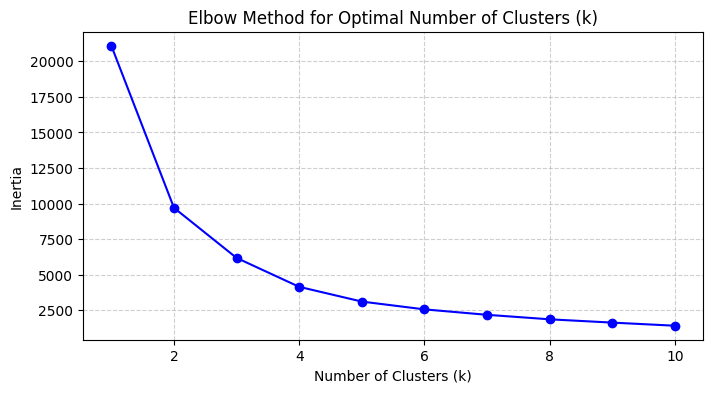

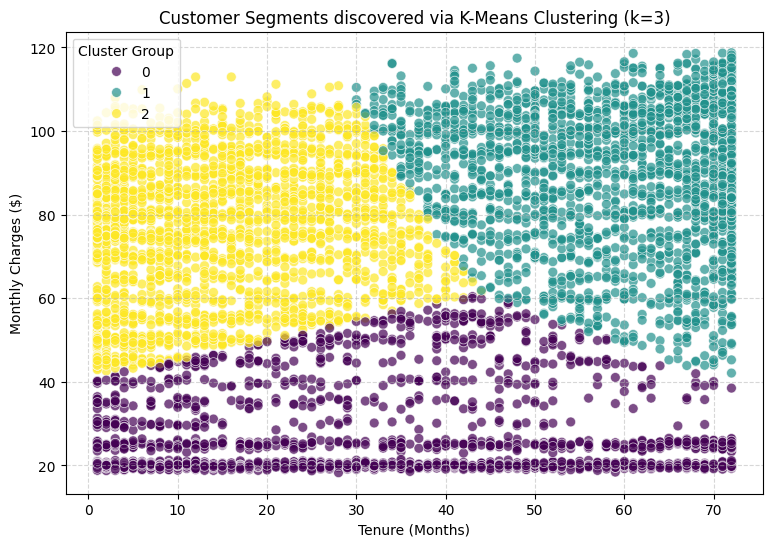


=== Cluster Characteristics Summary (Mean Values) ===


,tenure,MonthlyCharges,TotalCharges
Cluster,,,
0,29.620642,26.632241,815.255649
1,58.570323,89.743719,5249.427014
2,13.262668,74.965760,1031.878782


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import files
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load Dataset
print(
    "Please upload your 'WA_Fn-UseC_-Telco-Customer-Churn.csv' file if not already loaded:"
)
try:
    df.head()
    print("Using existing DataFrame in memory.")
except NameError:
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    df = pd.read_csv(filename)

# 2. Preprocessing & Feature Selection
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"])

# Select numerical variables to investigate
features = ["tenure", "MonthlyCharges", "TotalCharges"]
X_raw = df[features]

# features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 3. Explore different numbers of clusters using the Elbow Method
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker="o", linestyle="-", color="b")
plt.title("Elbow Method for Optimal Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 4. (k = 3 based on elbow curve)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Visualize the clusters using a scatter plot (Tenure vs Monthly Charges)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Cluster",
    palette="viridis",
    alpha=0.7,
    s=50,
)
plt.title(
    f"Customer Segments discovered via K-Means Clustering (k={optimal_k})"
)
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges ($)")
plt.legend(title="Cluster Group")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 6. Display cluster characteristics summary
cluster_summary = df.groupby("Cluster")[features].mean()
print("\n=== Cluster Characteristics Summary (Mean Values) ===")
display(cluster_summary)

## 2. Cluster Characteristics and Business Interpretation

### Characteristics of the Identified Groups ($k = 3$):
* **Cluster 0 (New / Low-Value Customers):** Characterized by short `tenure` (low number of months) and relatively lower `MonthlyCharges`. These represent newly acquired subscribers who are still evaluating the service.
* **Cluster 1 (High-Value Loyal Customers):** Characterized by long `tenure` and high `MonthlyCharges` / `TotalCharges`. These represent premium, long-term subscribers who use multiple high-tier services (such as streaming and security bundles).
* **Cluster 2 (Mid-Tier / Standard Users):** Characterized by moderate `tenure` and medium-to-high `MonthlyCharges`, representing the steady, core subscriber base.

### What do these patterns represent?
Unsupervised clustering successfully segments the customer base into distinct behavioral tiers without relying on the target label (`Churn`).
* In a business context, these clusters highlight natural customer archetypes. For instance, **Cluster 0** represents a critical high-risk group where introductory churn is most common, whereas **Cluster 1** represents highly profitable, established clients who require targeted loyalty incentives rather than basic onboarding assistance.